# Imports

In [48]:
import numpy as np

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, accuracy_score
from sklearn.metrics import auc
from matplotlib import pyplot as plt


# Treinando Random Forest Classifier

In [24]:
#gerando o dataset sintético
x, y = make_classification(n_samples = 1000,
                           n_classes = 2,
                           random_state = 1

)

#fazendo o split dos dados de treino e test
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.5, stratify = y, random_state = 2)

#definindo os parametros e treinando
model = RandomForestClassifier(n_estimators = 100,
                               max_depth = 2,
                               random_state = 0
)

model.fit(x_train, y_train)

y_scores = model.predict_proba(x_test)[:, 1]

# Calculando e Plotando a curva ROC


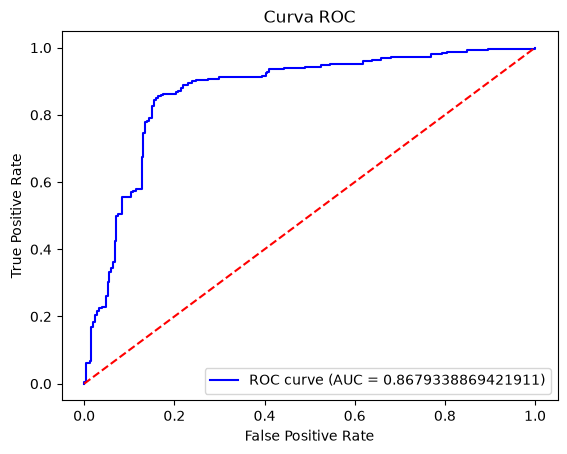

In [30]:
#calculando os valores da curva de roc
fpr, tpr, th = roc_curve(y_test, y_scores)

#calculando AUC score (metrica que mede a area debaixo da curva ROC. QUando mais próximo de 1 melhor)
auc_score = roc_auc_score(y_test, y_scores)

#plotando a curva ROC
plt.plot(fpr, tpr, color = 'b', label = f'ROC curve (AUC = {auc_score})')
plt.plot([0, 1], [0, 1], color = 'r', linestyle = '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC')
plt.legend()
plt.show()


# Escolhendo o melhor threshold da Curva ROC

In [46]:
#calculando as distancias dos pontos FP e TP. Na maior distancia é onde passa o melhor TH
distances = np.sqrt((1 - tpr)**2 + (fpr)**2)

#achando o melhor TH
best_th = th[np.argmin(distances)]

print(f'O melhor Th é: {best_th}')

O melhor Th é: 0.5436332486960381


# Medindo a Acurácia

In [ ]:
#mostrando pro modelo que os valores acima do TH é o que vão ser considerados positivos pelo predição
y_pred = (y_scores >= best_th).astype(int)

#calculando acurácia
accuracy = accuracy_score(y_test, y_pred)

print(f'A Acurácia é de: {accuracy}')

A Acurácia é de: 0.846
